# Project: Quantum Lock

## Questions

## Quantum lock prototype:

In [2]:
# qiskit lib
from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit.circuit.library import DiagonalGate
from qiskit.quantum_info import Statevector
# from qiskit.result.ProbDistribution import probabilities_dict
from IPython.display import display

# general math
from math import pi
import numpy as np
from random import Random
import itertools

# system information 
BINARY_PHASES = True
MESSAGE_QUBITS = 6
KEY_BITS = 2



# generate all message-key combinations (split into correct/incorrect key)
def all_message_key_pairs() -> [(int, int, int)]:
    message_key_pairs = list(itertools.product(range(0, 2**MESSAGE_QUBITS), range(0, 2**KEY_BITS), range(0, 2**KEY_BITS)))

    # returns [(message, key_enc, key_dec)] => 64 * 4 * 4 = 1024 combs
    return message_key_pairs


# generates the random phases
def generate_random_phases(key: int) -> [int]:
    d = 2**MESSAGE_QUBITS
    generator = Random(key)
    random_phases = [generator.randrange(2) * pi for _ in range(d)]

    return random_phases

# locks the state 
def encode_message(circuit: QuantumCircuit, message: int, key: int):
    # create the random phases using the key as the seed
    random_phases = generate_random_phases(key)

    # initialize the message into the quantum circuit (little endian, hence the [::-1])
    for qubit_num, qubit_val in enumerate(format(message, f'0{MESSAGE_QUBITS}b')[::-1]):
        circuit.initialize([1 ^ int(qubit_val), 0 ^ int(qubit_val)], qubit_num)

    # add the qft gate
    circuit.compose(QFTGate(MESSAGE_QUBITS), inplace=True)

    # create and add the diagonal gate
    diag_gate = DiagonalGate([np.exp(1j * phase) for phase in random_phases])
    circuit.compose(diag_gate, inplace=True)

    
# unlocks the state
def decode_message(circuit: QuantumCircuit, key: int):
    # create the random phases using the key as the seed
    random_phases = generate_random_phases(key)

    # inverse the diagonal gate
    diag_gate_inv = DiagonalGate([np.exp(1j * (-phase)) for phase in random_phases])
    circuit.compose(diag_gate_inv, inplace=True)
    
    # add inverse qft
    circuit.compose(QFTGate(MESSAGE_QUBITS).inverse(), inplace=True)


# assumes that the circuit is already built, and returns the message distribution
def get_message_probs(circuit: QuantumCircuit) -> dict:
    vec = Statevector(circuit)
    return vec.probabilities_dict()

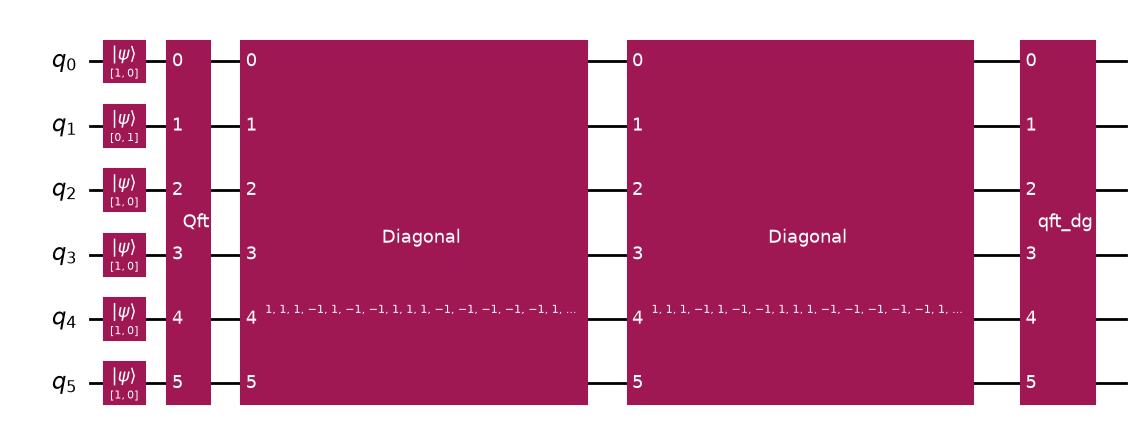

In [3]:
circuit = QuantumCircuit(MESSAGE_QUBITS)
encode_message(circuit, 0b010, 0b10)
decode_message(circuit, 0b10)
circuit.draw("mpl")

### Average decoding with correct key probability

In [2]:
def correct_key_stat() -> float:
    correct_keys = list(filter(lambda x: x[1] == x[2], all_message_key_pairs()))

    total_prob = 0

    for message, key_enc, key_dec in correct_keys:
        quantum_lock = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_lock, message, key_enc)
        decode_message(quantum_lock, key_dec)

        # magnitude squared
        c = Statevector(quantum_lock)[message]      # This slows the performance down by a lot
        total_prob += c.real ** 2 + c.imag ** 2

    avg = total_prob/len(correct_keys)
    return avg

print(f"The average correct message decoding probability (correct key): {correct_key_stat() * 100:.2f}%")

The average correct message decoding probability (correct key): 100.00%


### Average decoding with incorrect key probability

In [3]:
def wrong_key_stat() -> float:
    wrong_keys = list(filter(lambda x: x[1] != x[2], all_message_key_pairs()))

    total_prob = 0
    
    for message, key_enc, key_dec in wrong_keys:
        quantum_lock = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_lock, message, key_enc)
        decode_message(quantum_lock, key_dec)

        # magnitude squared
        c = Statevector(quantum_lock)[message]    # This slows the performance down by a lot
        total_prob += c.real ** 2 + c.imag ** 2

    avg = total_prob/len(wrong_keys)
    return avg

print(f"The average correct message decoding probability (incorrect key): {wrong_key_stat() * 100:.2f}%")

The average correct message decoding probability (incorrect key): 0.63%


### Probability distribution of selected messages

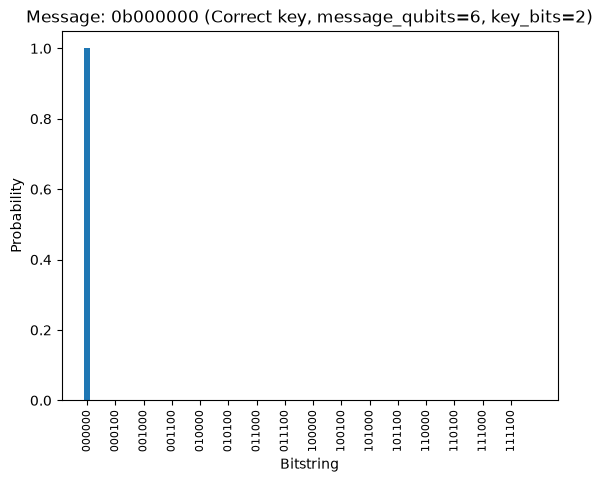

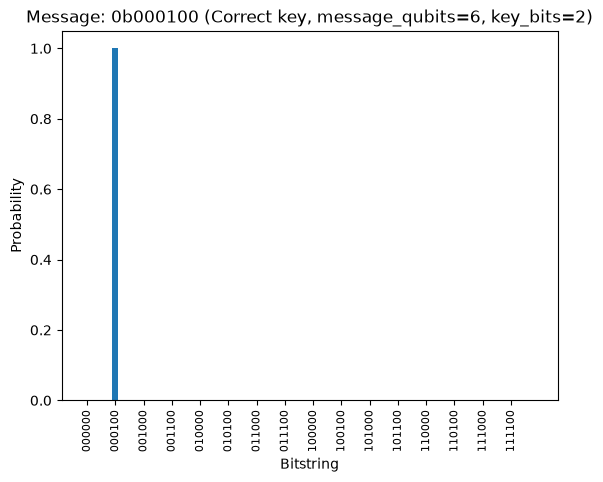

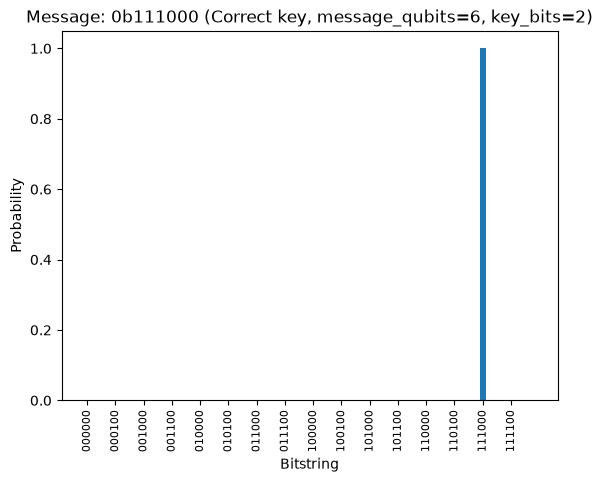

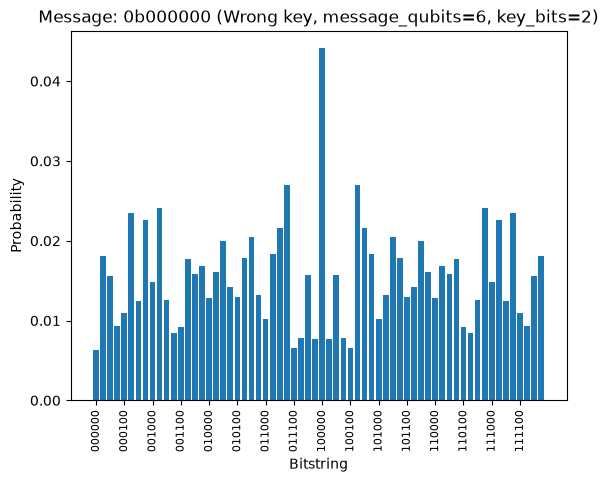

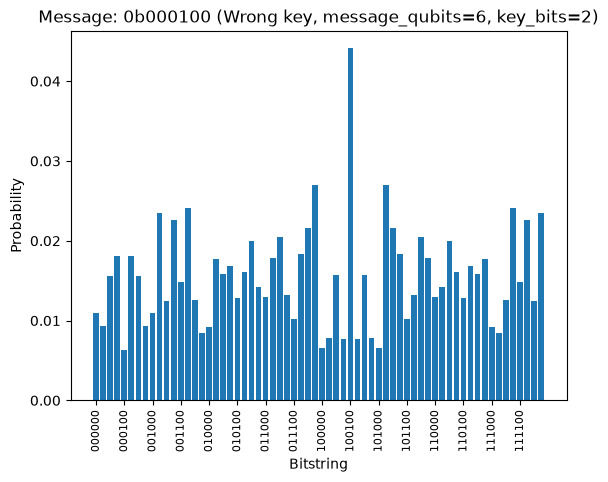

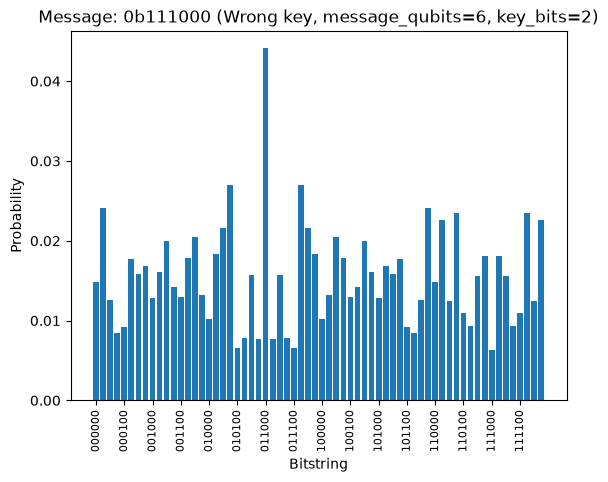

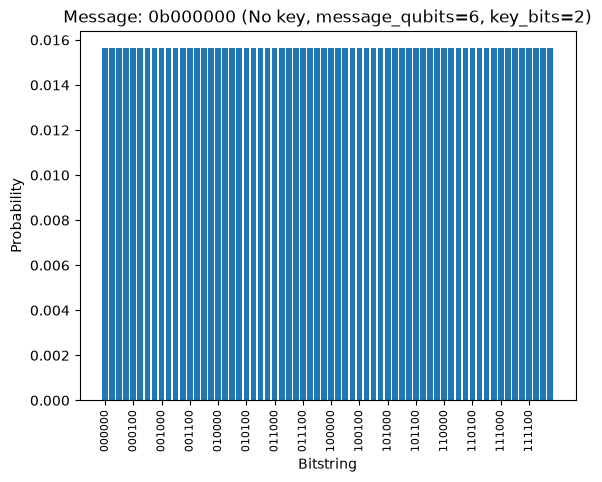

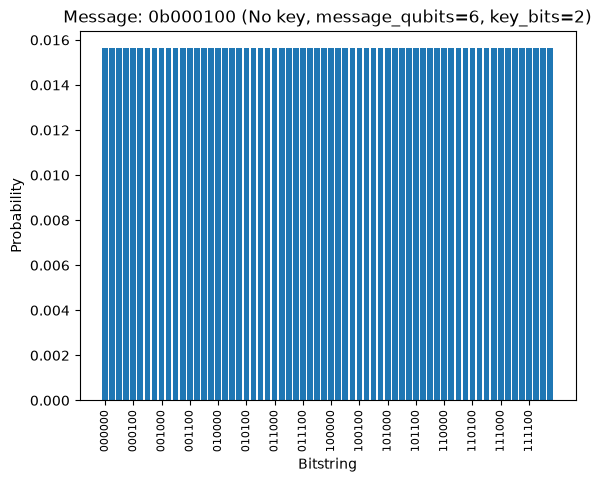

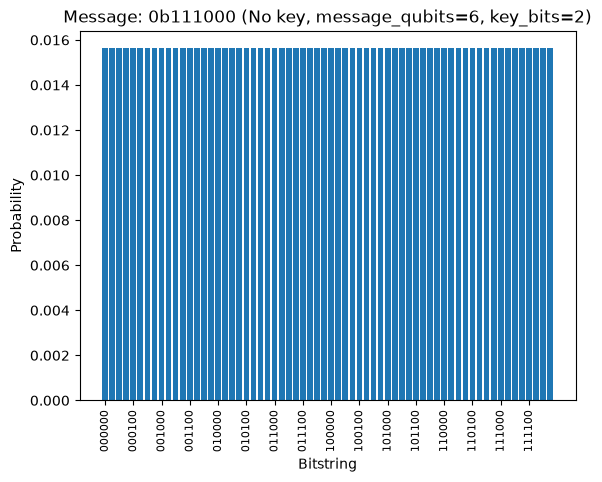

In [4]:
import matplotlib.pyplot as plt

# helper function to plot the outcomes of a message and given key pairs
def plot_distribution(message: int, keys: [(int, int)], label: str, no_key:bool=False):
    unnormalized_probs = {_message: 0.0 for _message in range(0, 2**MESSAGE_QUBITS)}

    for key_enc, key_dec in keys:
        quantum_circuit = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_circuit, message, key_enc)
        
        if (not no_key):
            decode_message(quantum_circuit, key_dec)

        probs = get_message_probs(quantum_circuit)
        unnormalized_probs = {_message: prob + probs[format(_message, f'0{MESSAGE_QUBITS}b')] for _message, prob in unnormalized_probs.items()}

    tot_prob = sum(unnormalized_probs.values())
    normalized_probs = {_message: prob/tot_prob for _message, prob in unnormalized_probs.items()}
    
    bitstrings = list(normalized_probs.keys())
    probabilities = list(normalized_probs.values())
    
    plt.bar(bitstrings, probabilities)
    plt.xticks(
        range(0, len(bitstrings), 4),
        list(map(lambda x: format(x, f'0{MESSAGE_QUBITS}b'), bitstrings))[::4],
        rotation=90,
        fontsize=8
    )
    
    plt.xlabel("Bitstring")
    plt.ylabel("Probability")
    plt.title(label)
    
    plt.show()


def selected_messages_stat(messages: [int]):
    messages = list(filter(lambda x: x < 2**MESSAGE_QUBITS, messages))
    
    all_keys_messages = all_message_key_pairs()
    
    # get all of the relevant messsages and their keys where key_enc == key_dec
    correct_key = {message: list(map(lambda x: x[1:], filter(lambda x: x[1] == x[2] and x[0] == message, all_keys_messages))) for message in messages}
    
    # get all of the relevant messsages and their keys where key_enc != key_dec
    wrong_key = {message: list(map(lambda x: x[1:], filter(lambda x: x[1] != x[2] and x[0] == message, all_keys_messages))) for message in messages}

    # plot the correct keys first
    for message, keys in correct_key.items():
        plot_distribution(message, keys, f"Message: 0b{format(message, f'0{MESSAGE_QUBITS}b')} (Correct key, message_qubits={MESSAGE_QUBITS}, key_bits={KEY_BITS})")

    # plot the wrong keys
    for message, keys in wrong_key.items():
        plot_distribution(message, keys, f"Message: 0b{format(message, f'0{MESSAGE_QUBITS}b')} (Wrong key, message_qubits={MESSAGE_QUBITS}, key_bits={KEY_BITS})")

    for message, keys in correct_key.items():
        plot_distribution(message, keys, f"Message: 0b{format(message, f'0{MESSAGE_QUBITS}b')} (No key, message_qubits={MESSAGE_QUBITS}, key_bits={KEY_BITS})", no_key=True)

            
# randomly selected 6 bit messages
selected_messages = [0b0, 0b100, 0b111000]
selected_messages_stat(selected_messages)

### Entropy of no key and wrong key

In [5]:
def shannon_entropy(probs: [float]) -> float:
    return -sum(prob * np.log2(prob) for prob in probs)

def entropy_stat():
    all_keys_messages = all_message_key_pairs()

    correct_keys = list(filter(lambda x: x[1] == x[2], all_keys_messages))
    wrong_keys = list(filter(lambda x: x[1] != x[2], all_keys_messages))
    no_keys = list(map(lambda x: (x[0], x[1]), correct_keys))

    tot_entropy_correct_key = 0
    tot_entropy_wrong_key = 0
    tot_entropy_no_key = 0

    print("Starting entropy calculation of correct keys...")
    # correct key
    for message, key_enc, key_dec in correct_keys:
        quantum_circuit = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_circuit, message, key_enc)
        decode_message(quantum_circuit, key_dec)
        
        # measure here
        tot_entropy_correct_key += shannon_entropy(get_message_probs(quantum_circuit).values())

    avg_entropy_correct_key = tot_entropy_correct_key/len(correct_keys)

    print("Starting entropy calculation of wrong keys...")
    # wrong key
    for message, key_enc, key_dec in wrong_keys:
        quantum_circuit = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_circuit, message, key_enc)
        decode_message(quantum_circuit, key_dec)
        
        # measure here
        tot_entropy_wrong_key += shannon_entropy(get_message_probs(quantum_circuit).values())

    avg_entropy_wrong_key = tot_entropy_wrong_key/len(wrong_keys)

    print("Starting entropy calculation of no keys...")
    # no key
    for message, key_enc in no_keys:
        quantum_circuit = QuantumCircuit(MESSAGE_QUBITS)
        encode_message(quantum_circuit, message, key_enc)
        
        # measure here
        tot_entropy_no_key += shannon_entropy(get_message_probs(quantum_circuit).values())

    avg_entropy_no_key = tot_entropy_no_key/len(no_keys)

    return avg_entropy_correct_key, avg_entropy_wrong_key, avg_entropy_no_key

entropy_avg = entropy_stat()
print(f"The averages of Shannon entropy (message qubits = {MESSAGE_QUBITS}, key bits = {KEY_BITS})")
print(f"Average entropy (correct keys): {entropy_avg[0]:.2f}")
print(f"Average entropy (wrong keys): {entropy_avg[1]:.2f}")
print(f"Average entropy (no keys): {entropy_avg[2]:.2f}")

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 6, key bits = 2)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 5.40
Average entropy (no keys): 6.00


### Results for different values of K and n.

Calculating for message_qubits=4, key_bits=1


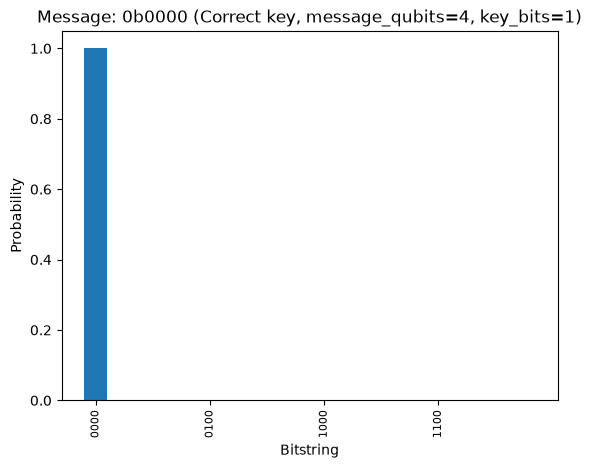

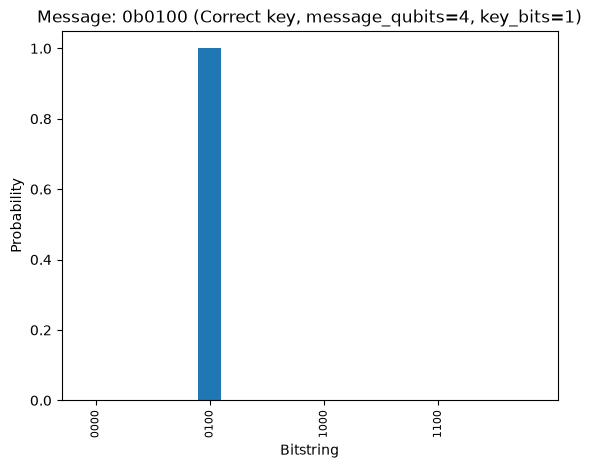

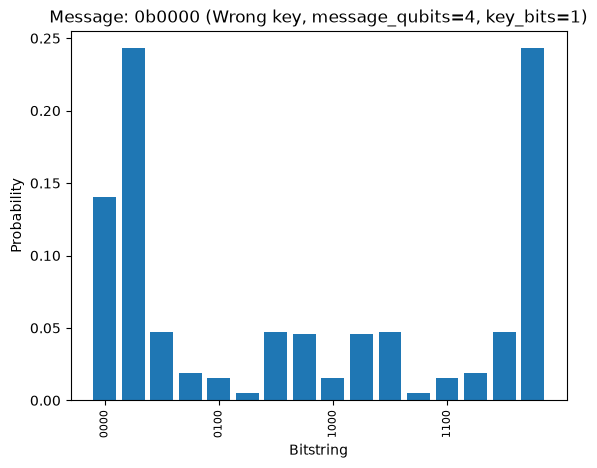

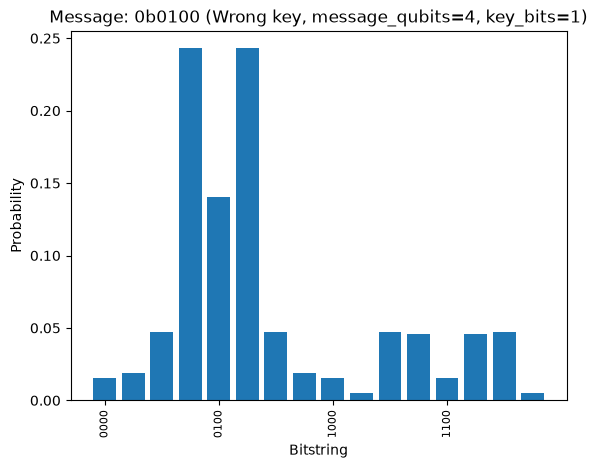

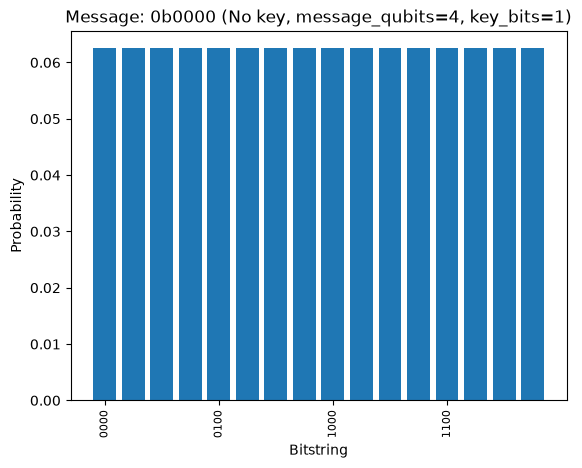

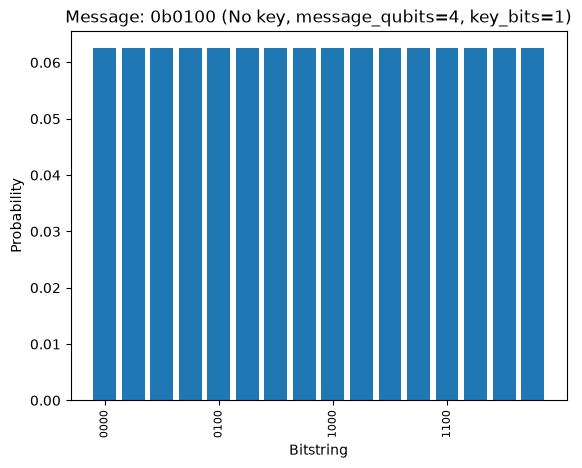

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 4, key bits = 1)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 3.20
Average entropy (no keys): 4.00
Calculating for message_qubits=4, key_bits=2


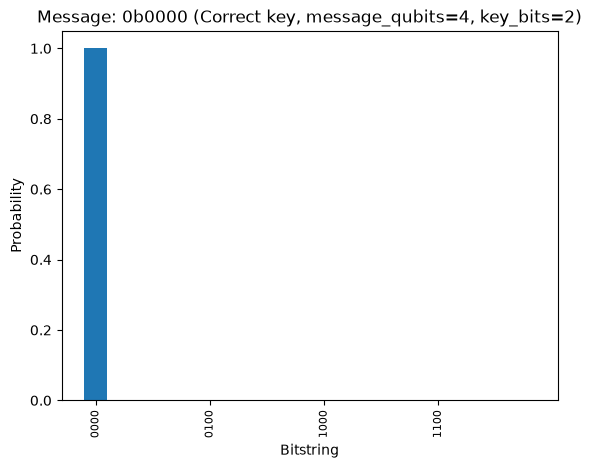

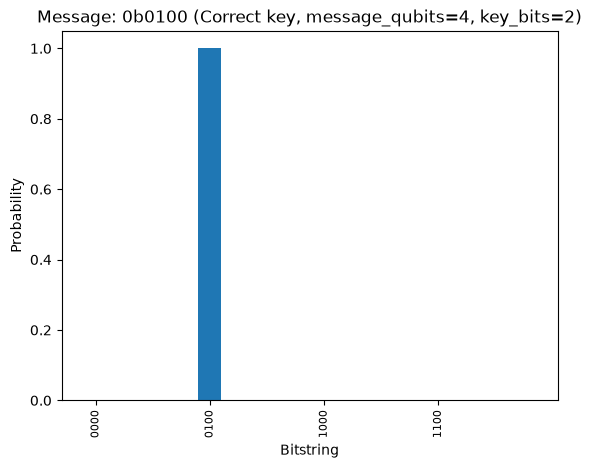

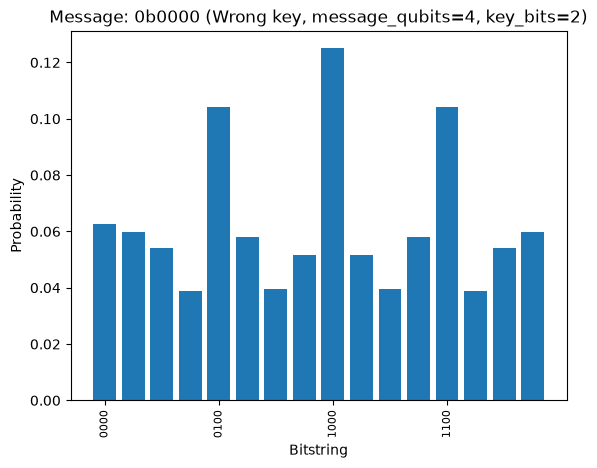

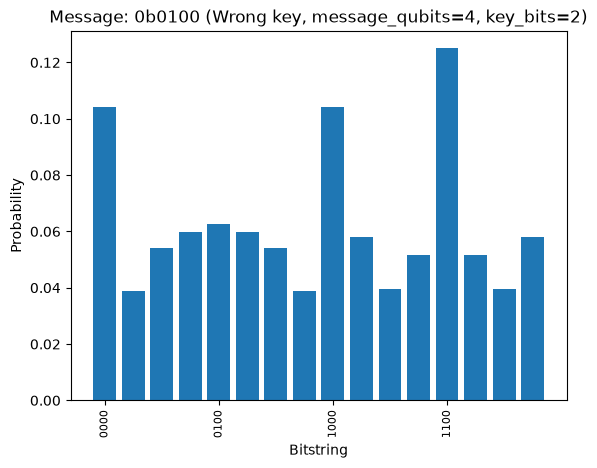

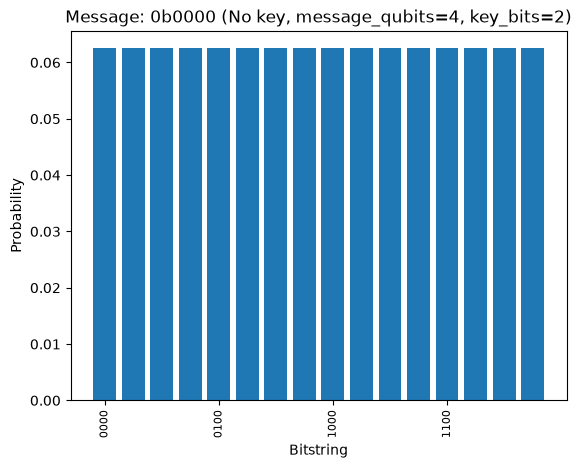

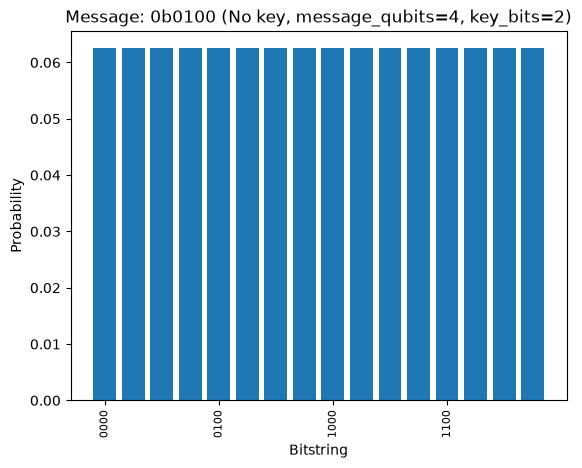

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 4, key bits = 2)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 3.32
Average entropy (no keys): 4.00
Calculating for message_qubits=4, key_bits=3


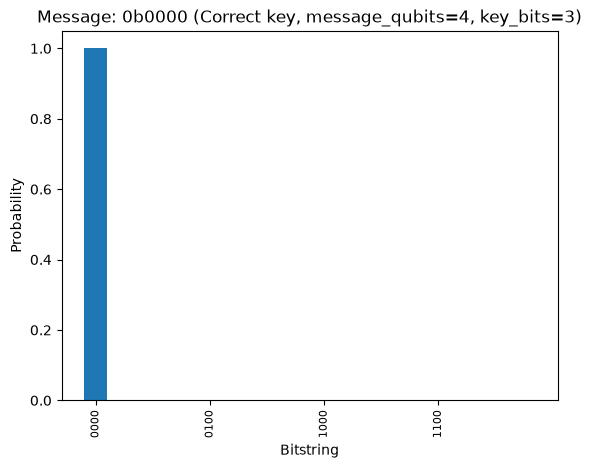

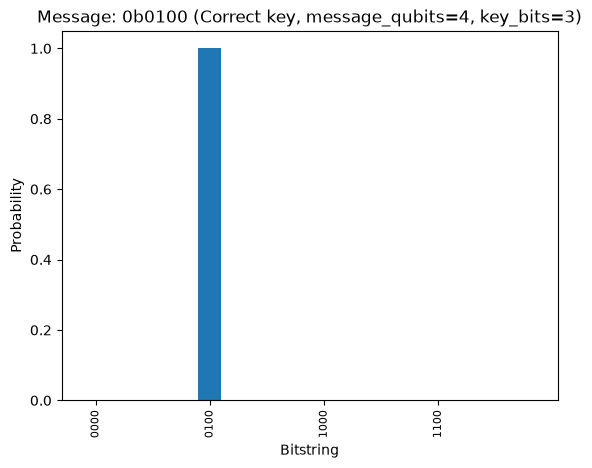

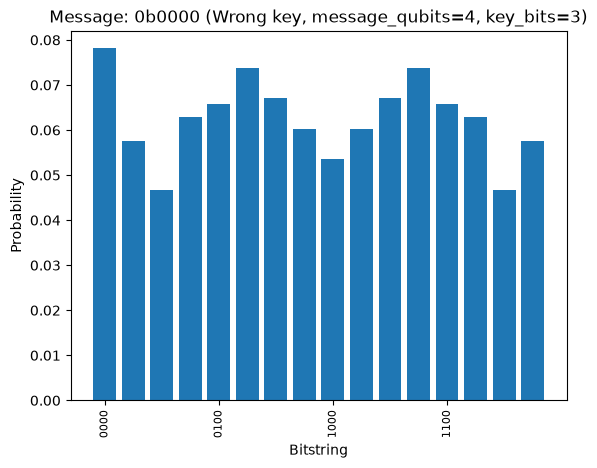

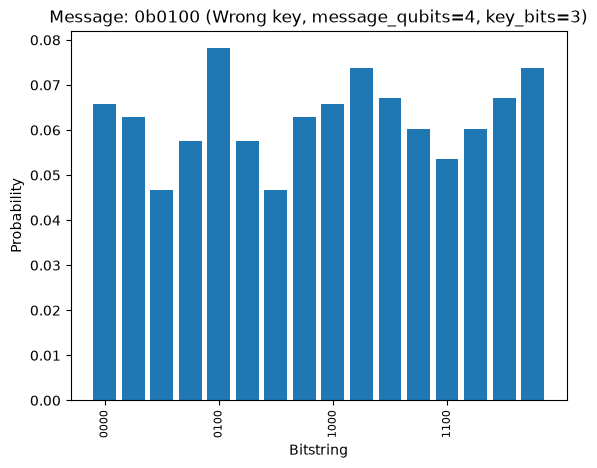

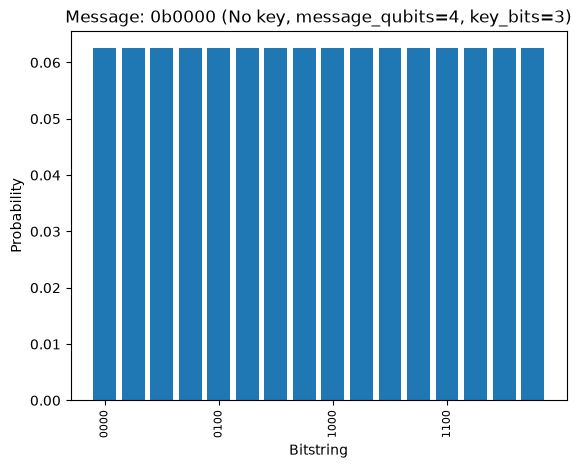

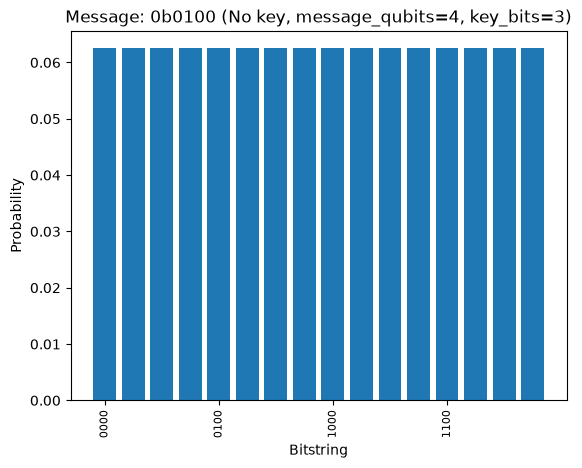

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 4, key bits = 3)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 3.35
Average entropy (no keys): 4.00
Calculating for message_qubits=5, key_bits=1


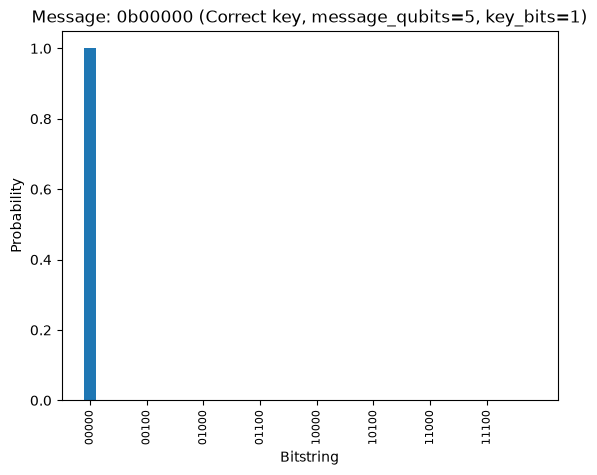

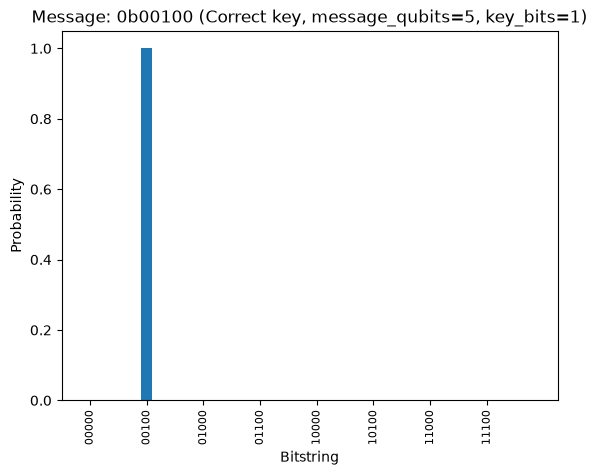

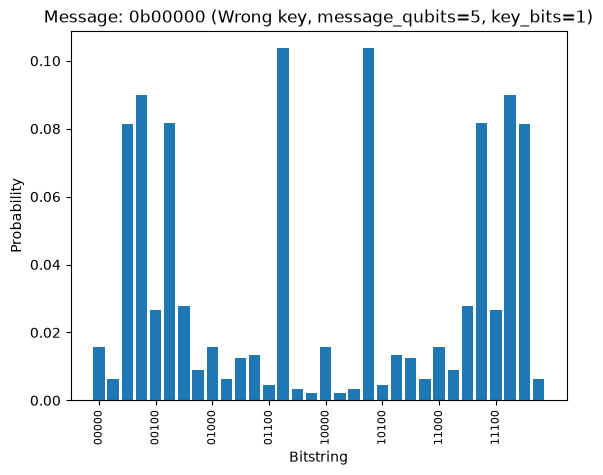

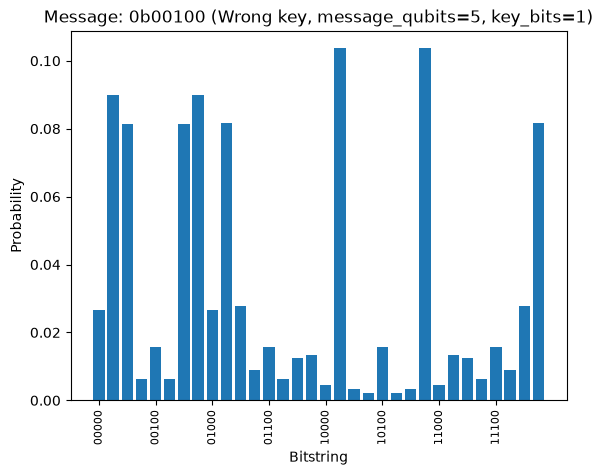

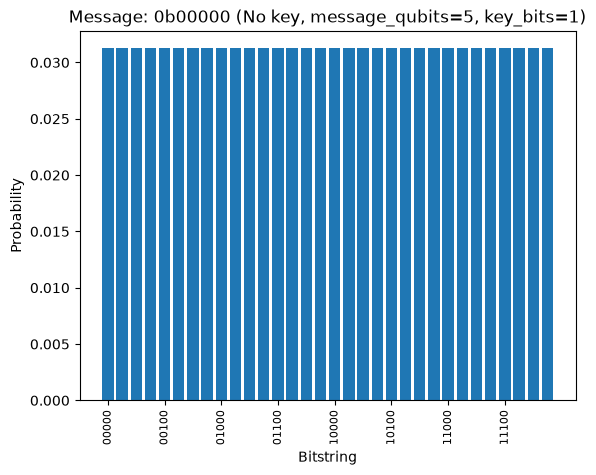

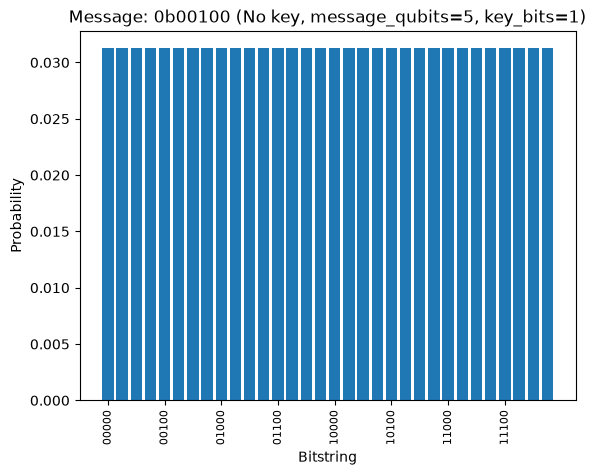

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 5, key bits = 1)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 4.22
Average entropy (no keys): 5.00
Calculating for message_qubits=5, key_bits=2


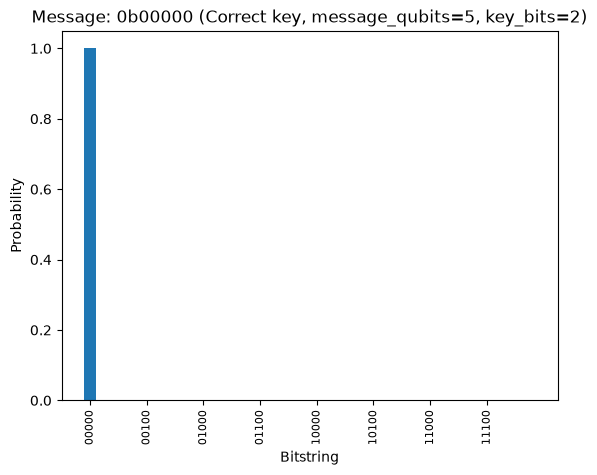

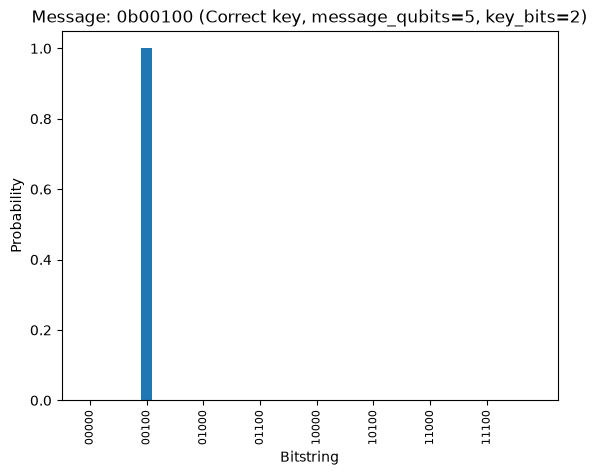

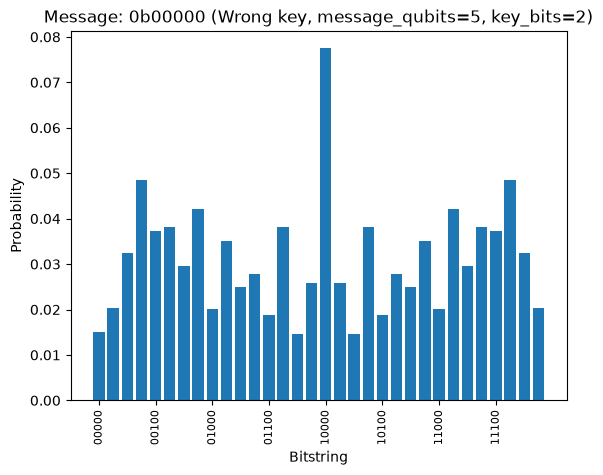

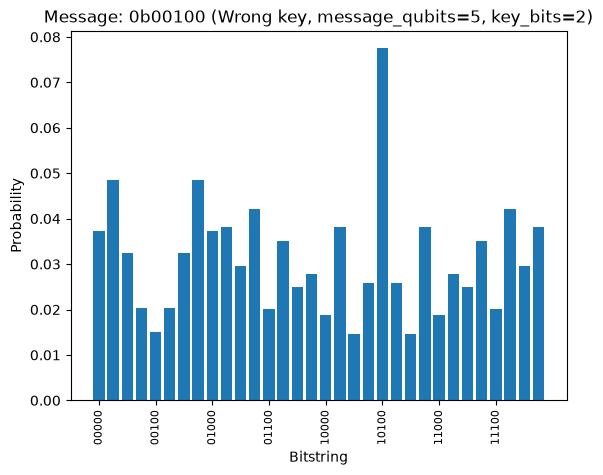

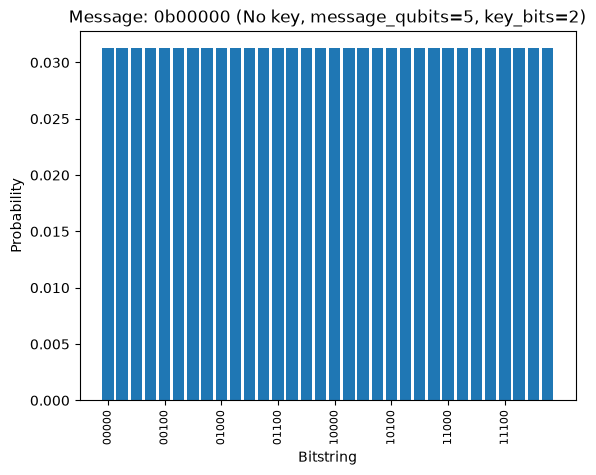

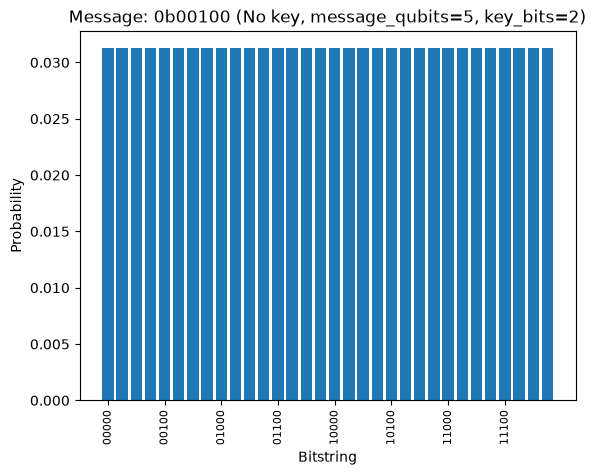

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 5, key bits = 2)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 4.32
Average entropy (no keys): 5.00
Calculating for message_qubits=5, key_bits=3


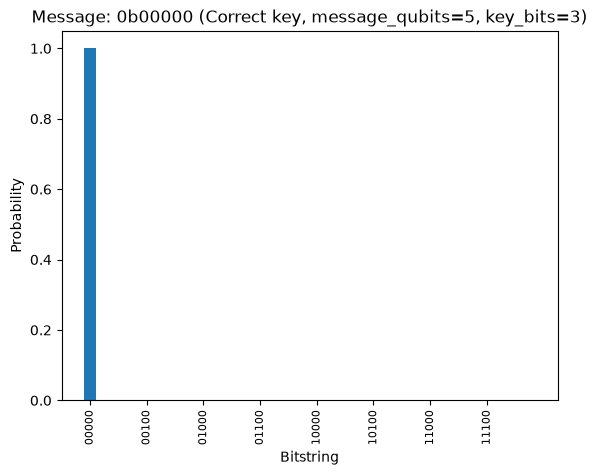

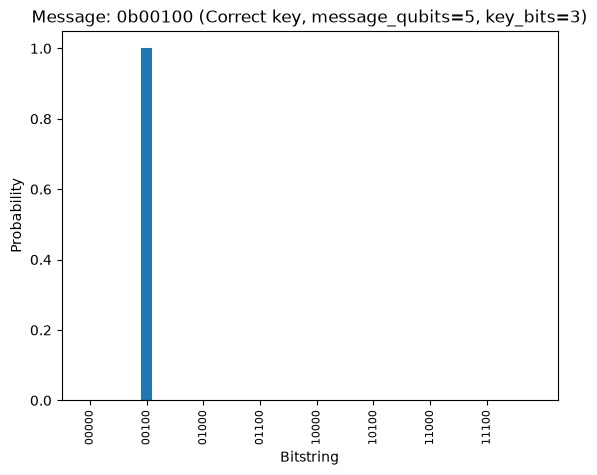

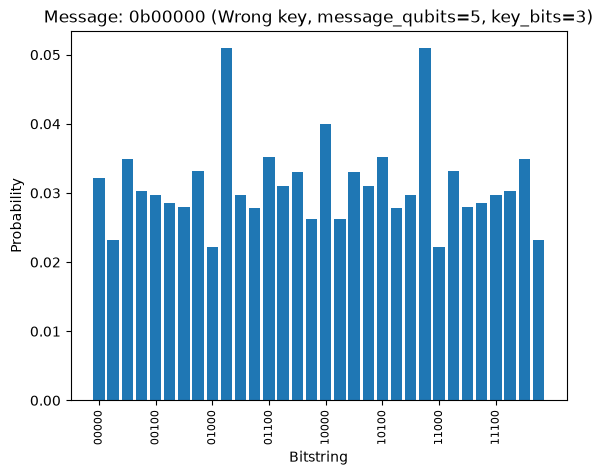

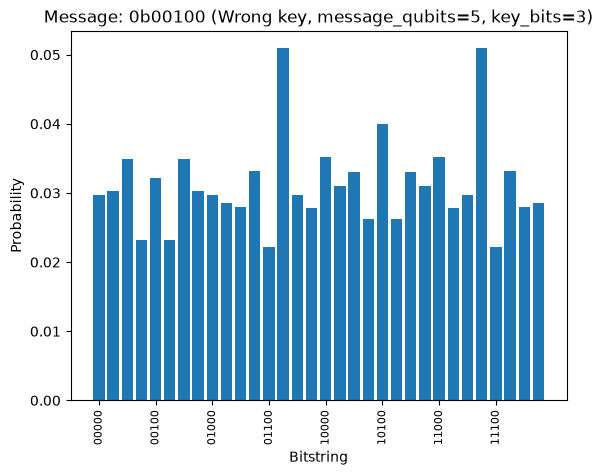

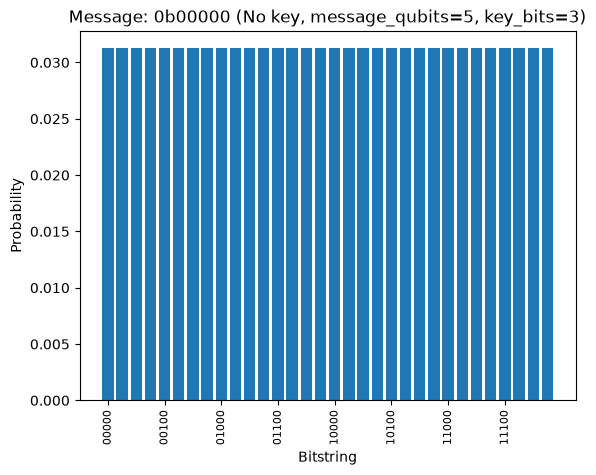

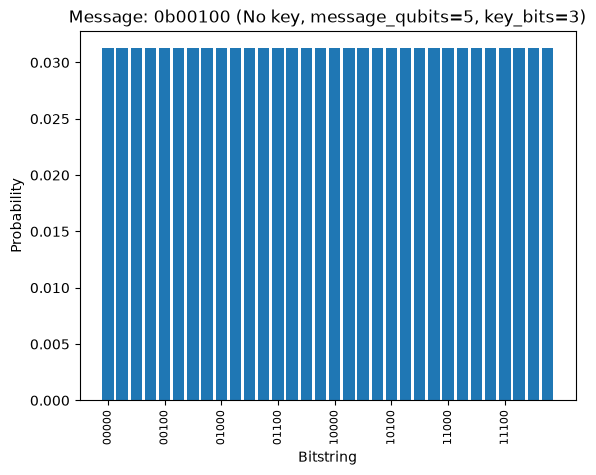

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 5, key bits = 3)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 4.36
Average entropy (no keys): 5.00
Calculating for message_qubits=6, key_bits=1


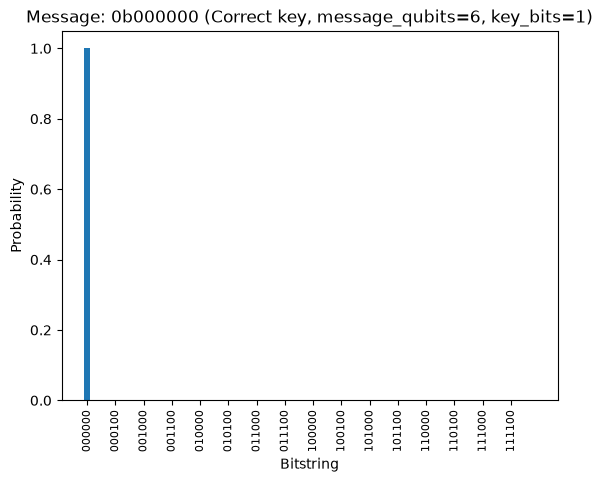

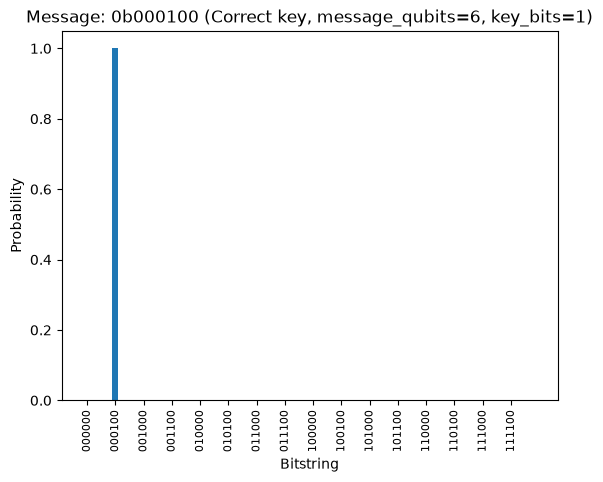

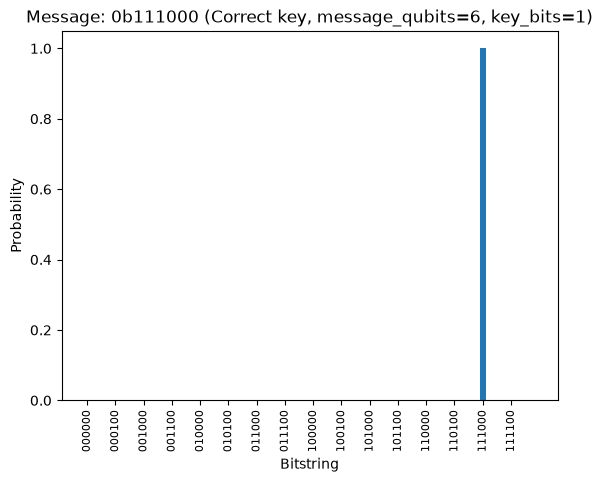

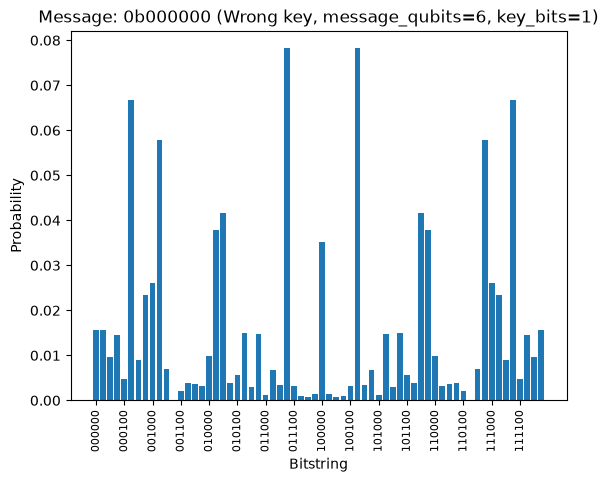

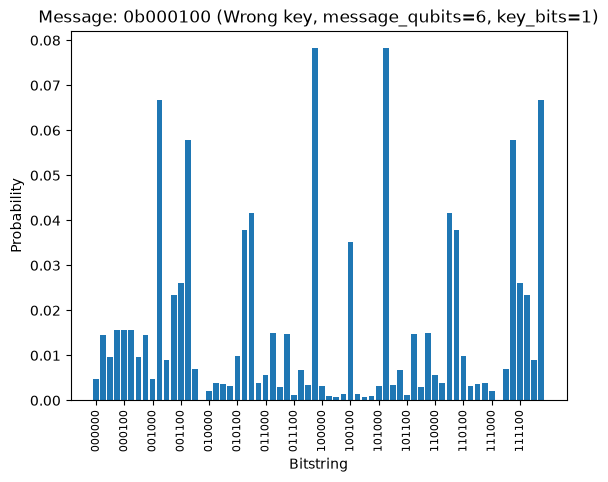

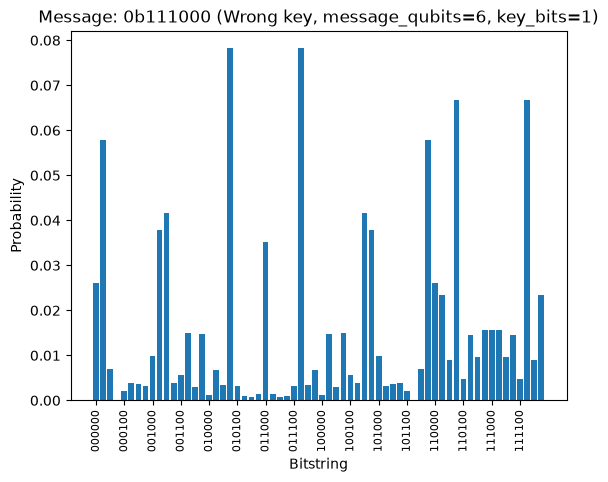

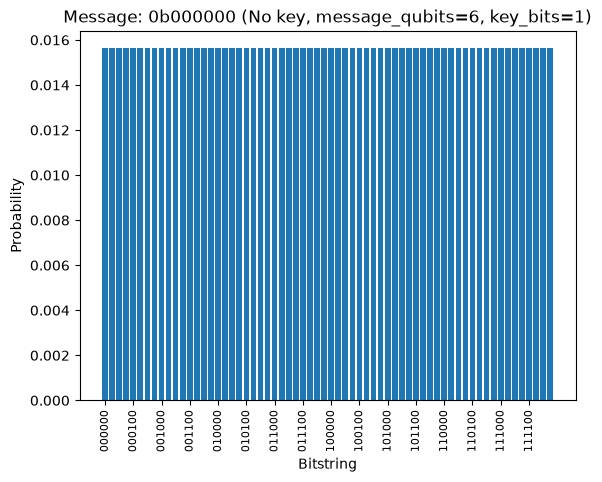

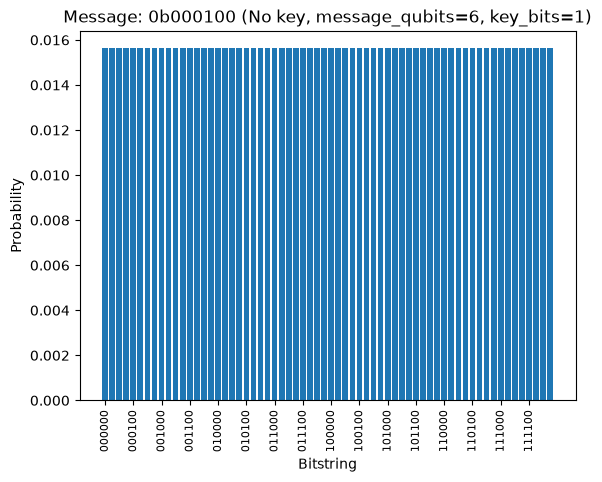

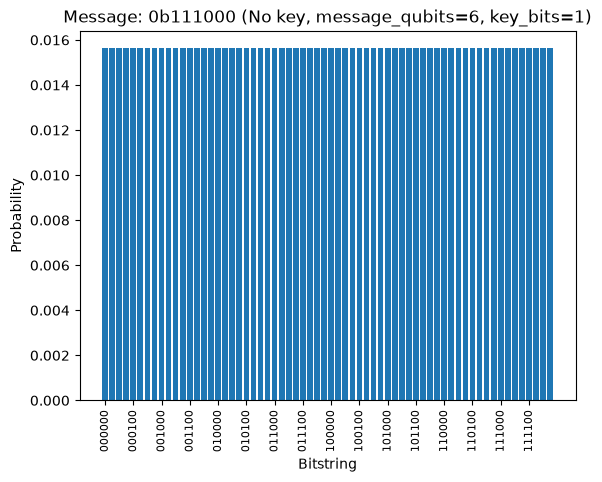

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 6, key bits = 1)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 5.08
Average entropy (no keys): 6.00
Calculating for message_qubits=6, key_bits=2


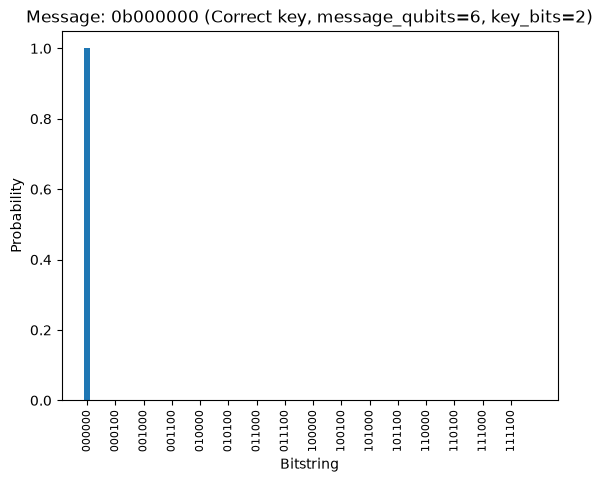

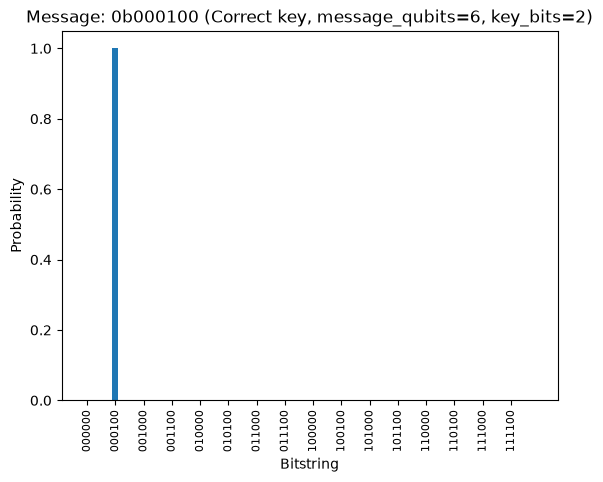

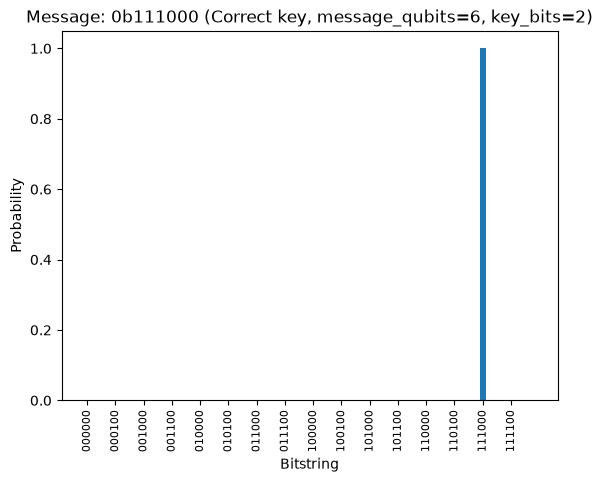

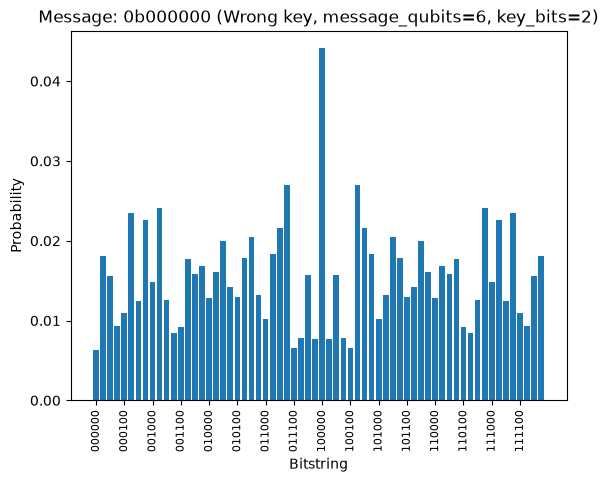

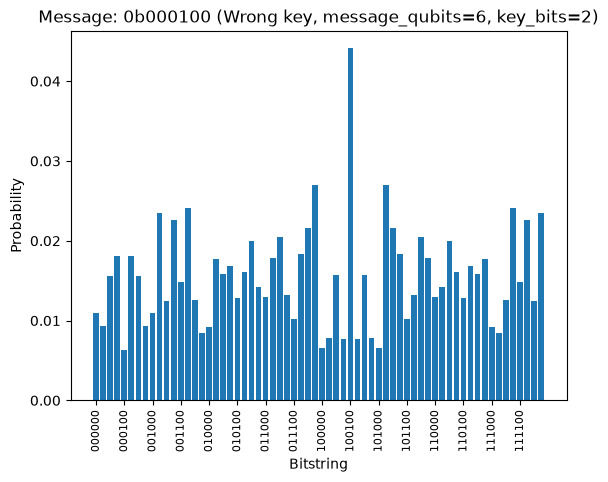

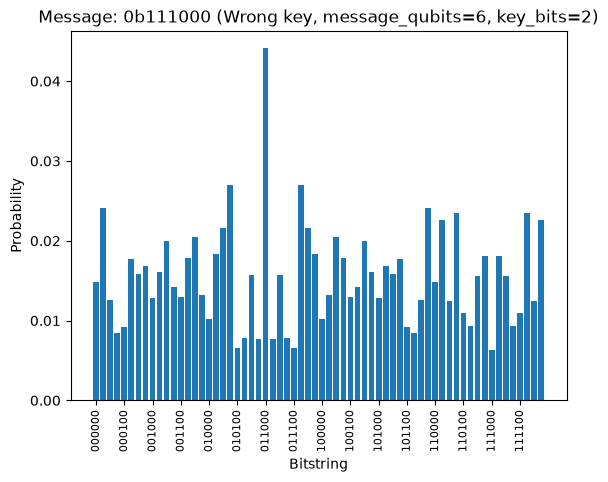

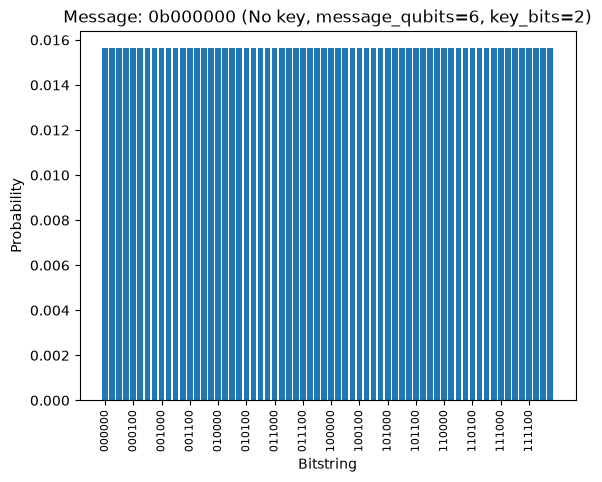

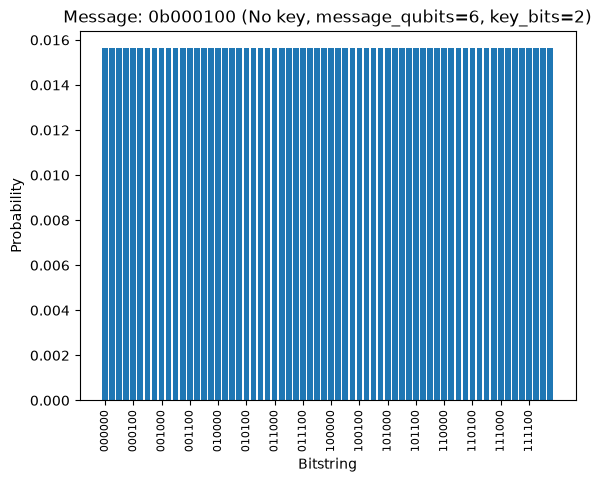

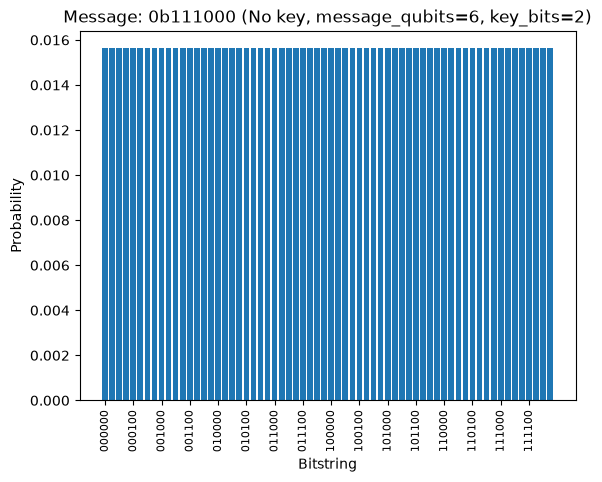

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 6, key bits = 2)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 5.40
Average entropy (no keys): 6.00
Calculating for message_qubits=6, key_bits=3


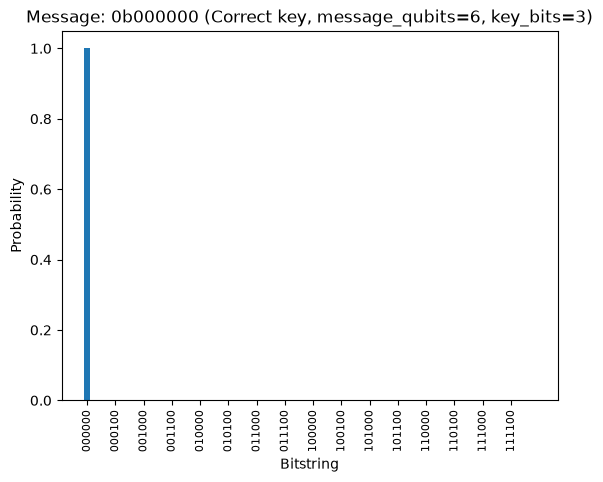

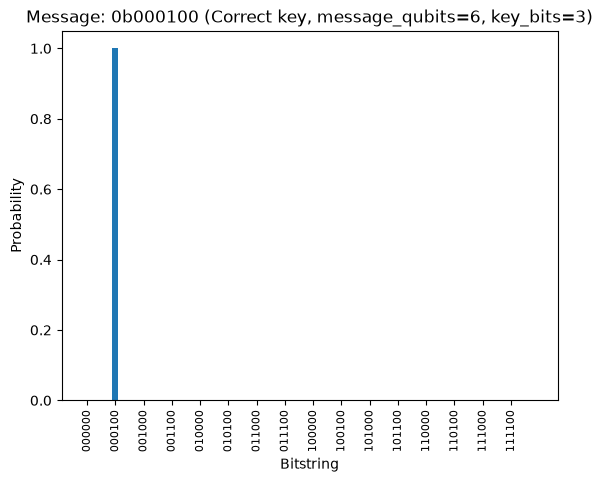

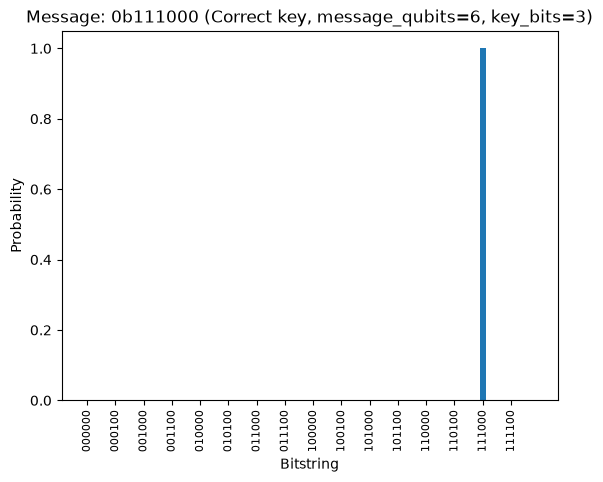

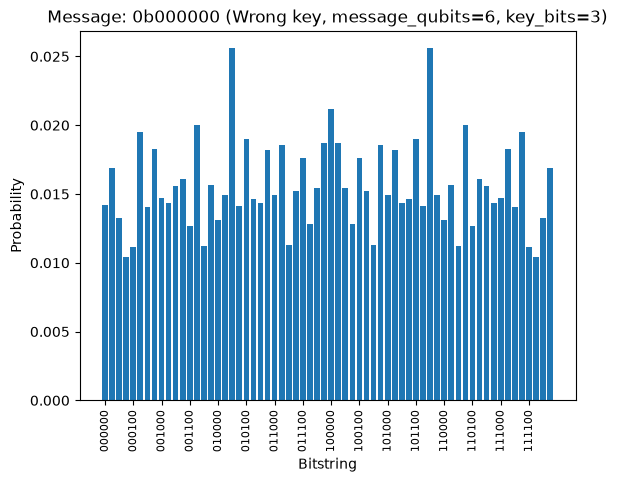

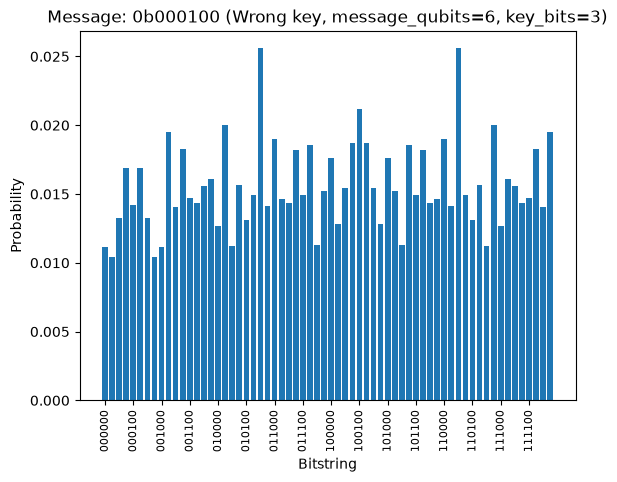

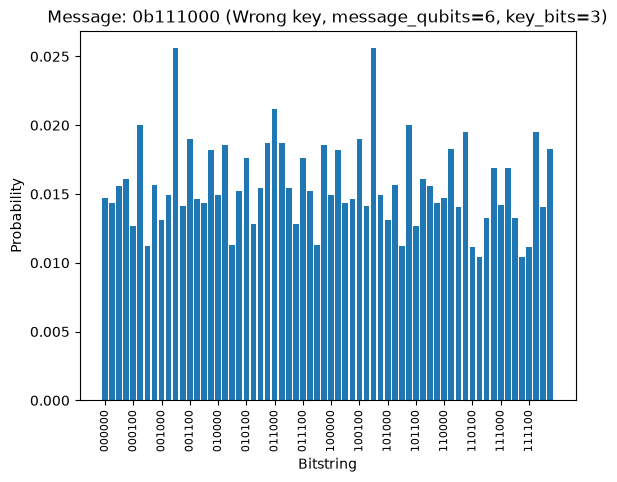

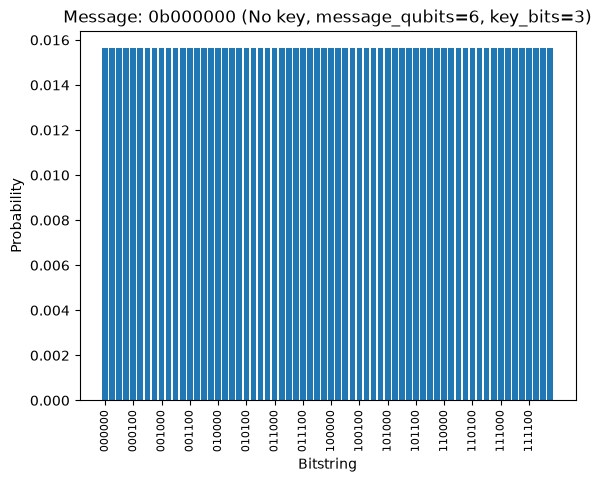

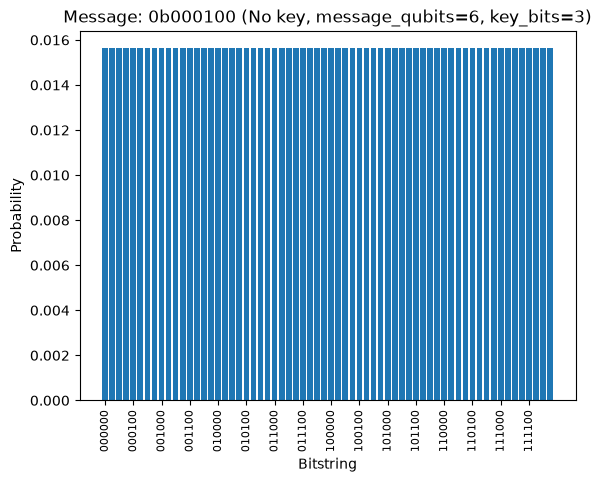

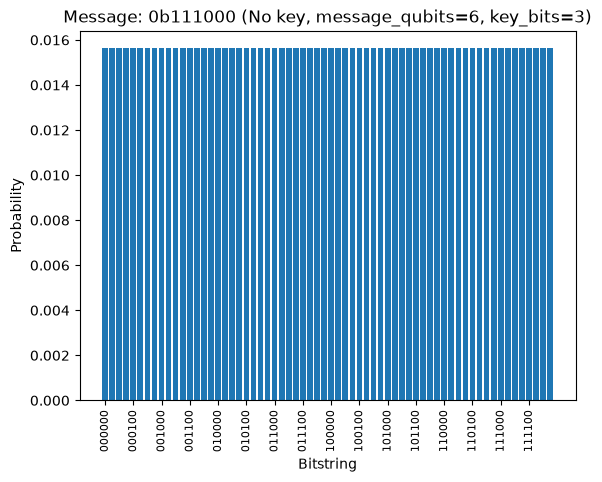

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 6, key bits = 3)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 5.35
Average entropy (no keys): 6.00
Calculating for message_qubits=7, key_bits=1


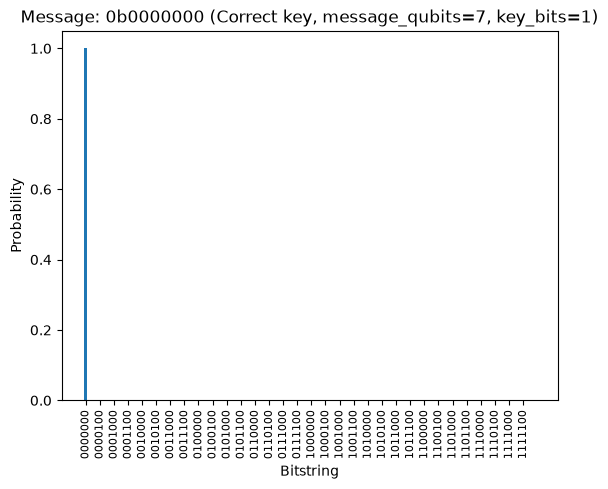

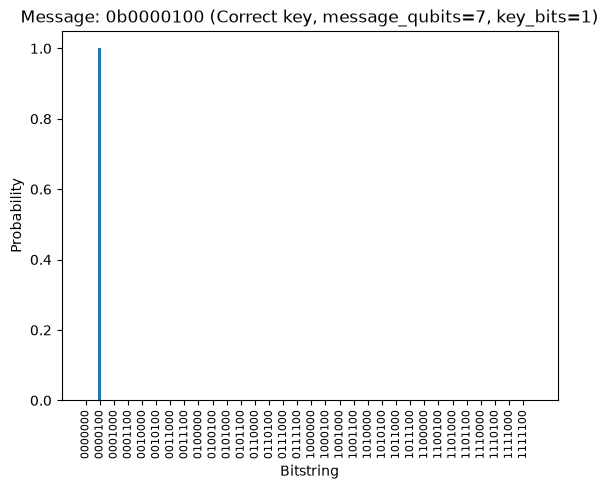

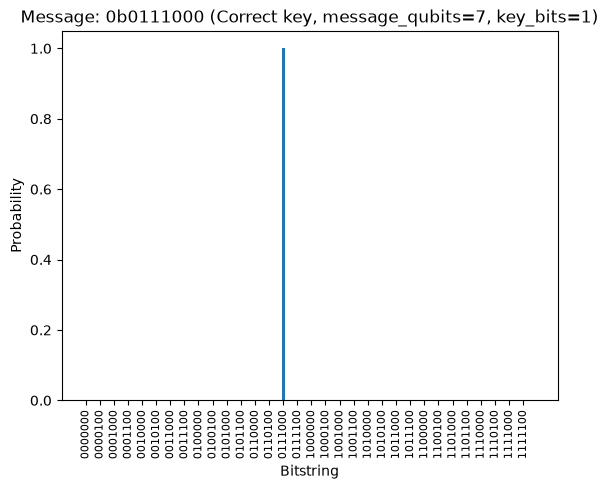

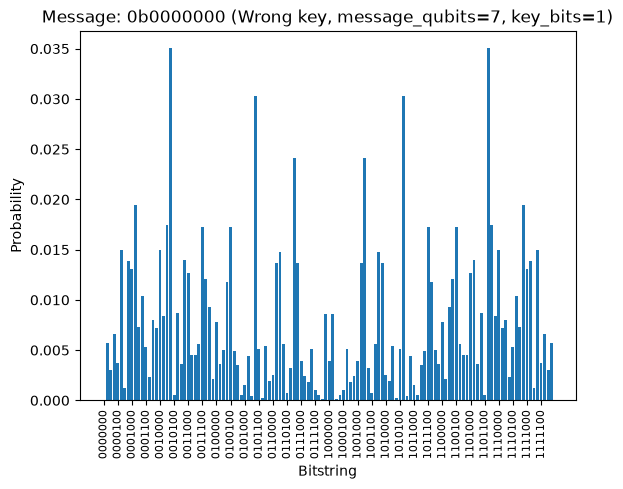

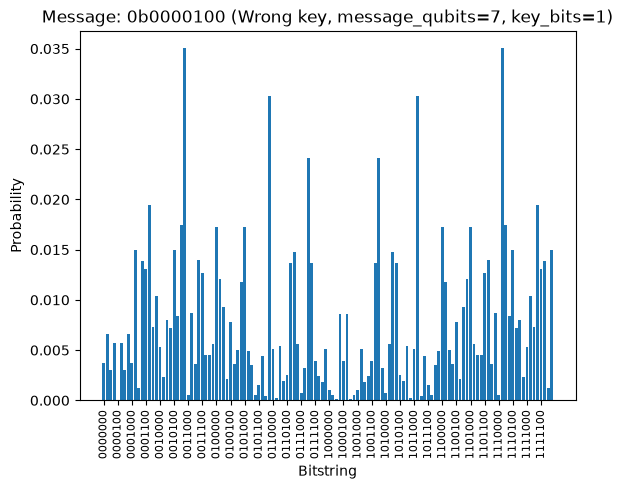

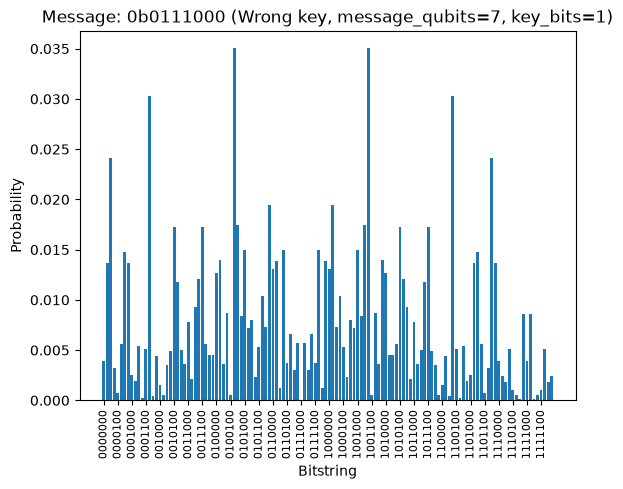

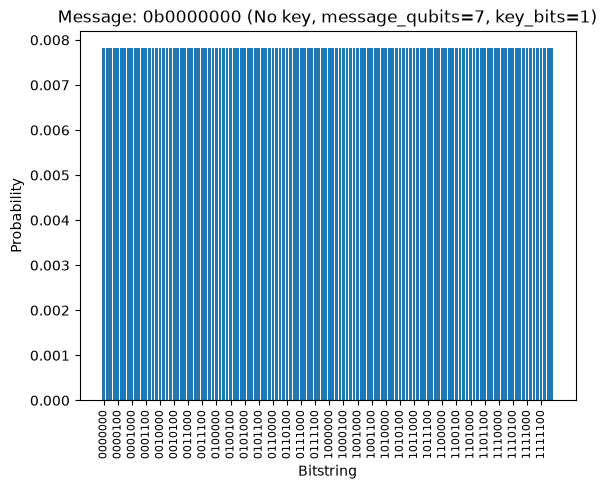

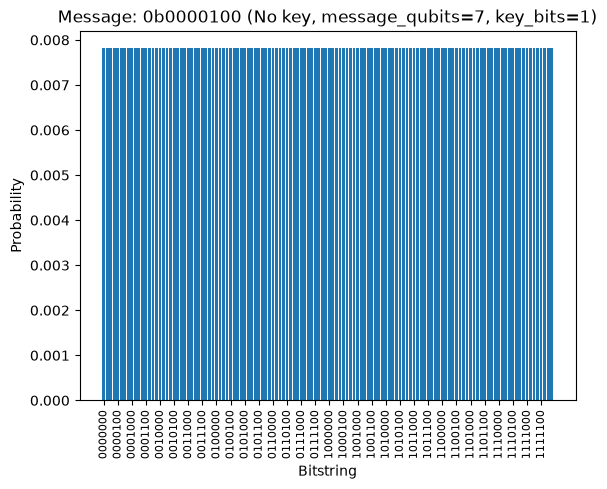

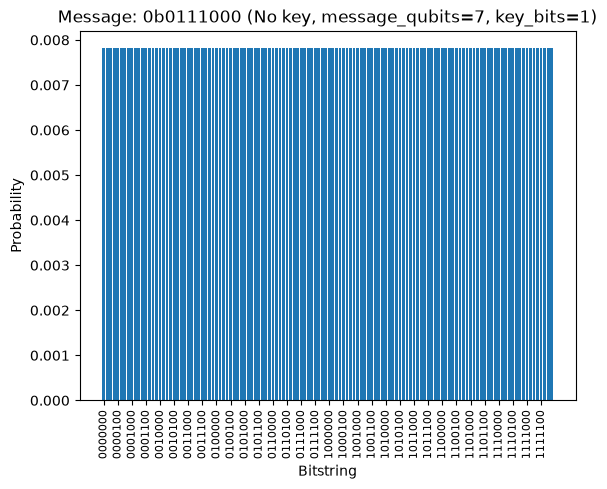

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 7, key bits = 1)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 6.45
Average entropy (no keys): 7.00
Calculating for message_qubits=7, key_bits=2


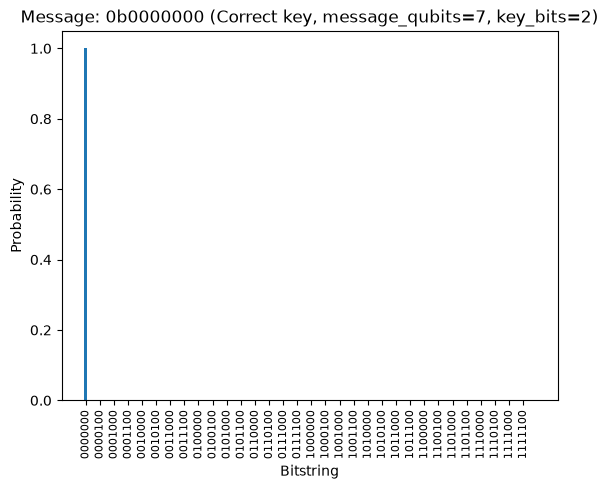

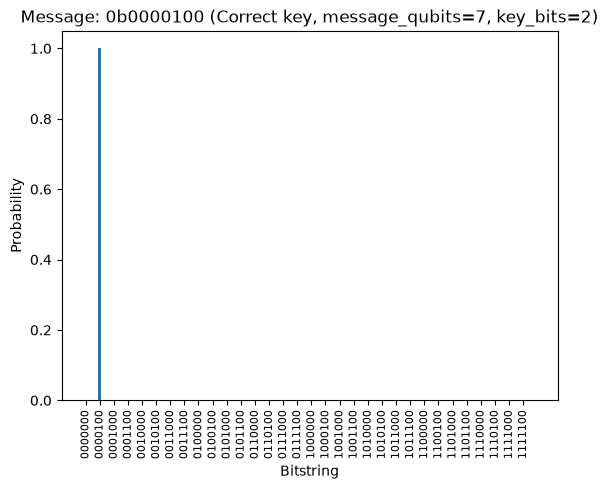

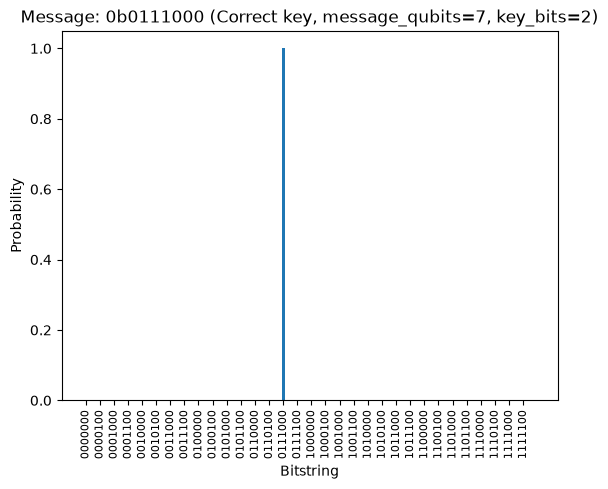

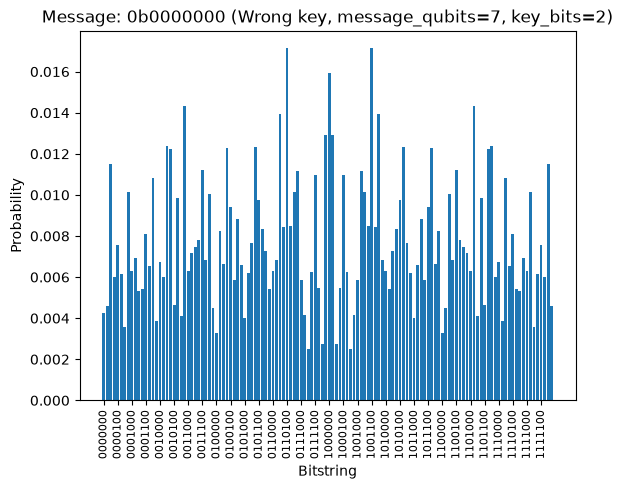

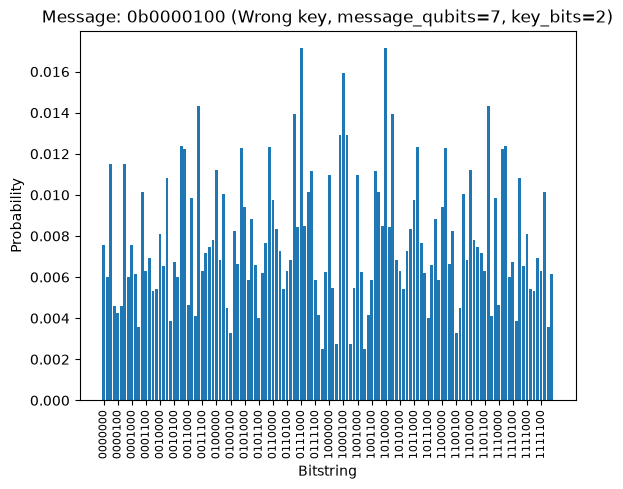

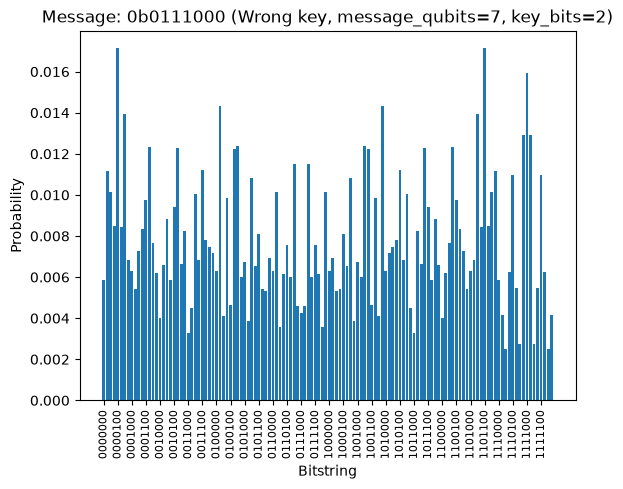

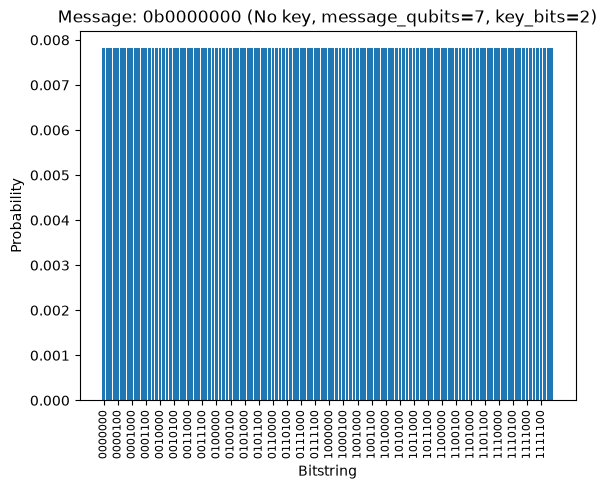

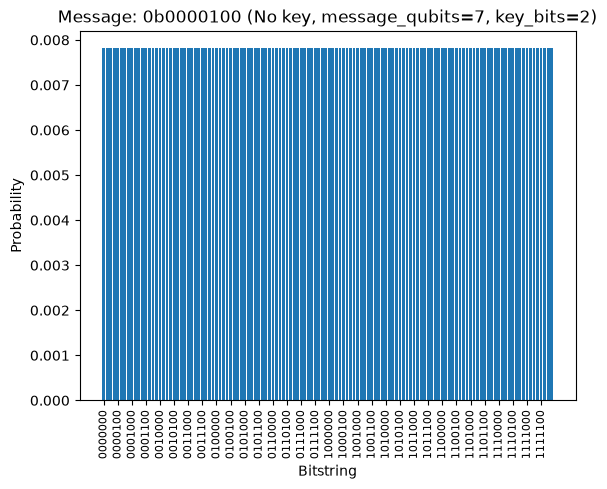

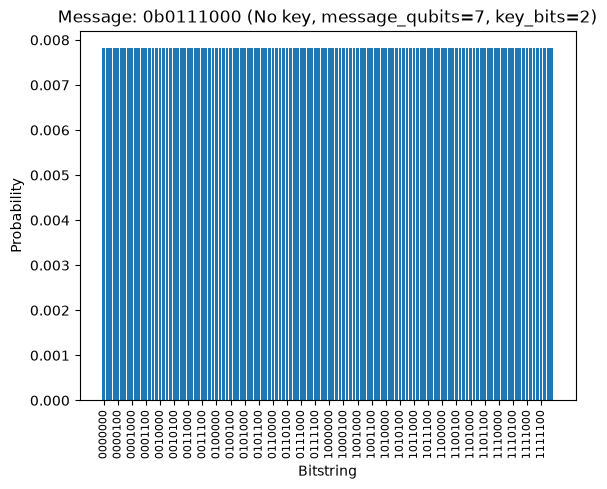

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 7, key bits = 2)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 6.41
Average entropy (no keys): 7.00
Calculating for message_qubits=7, key_bits=3


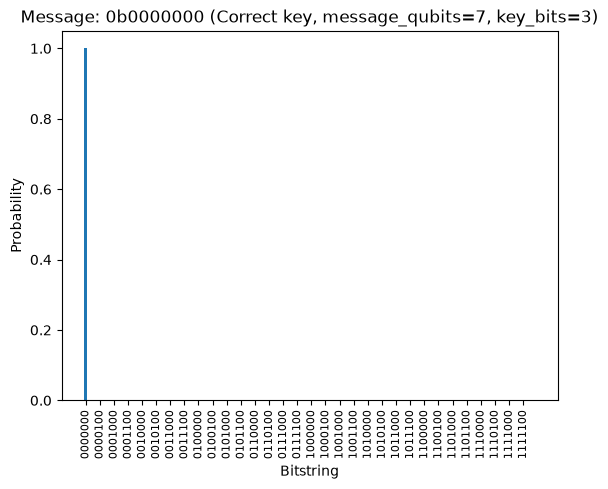

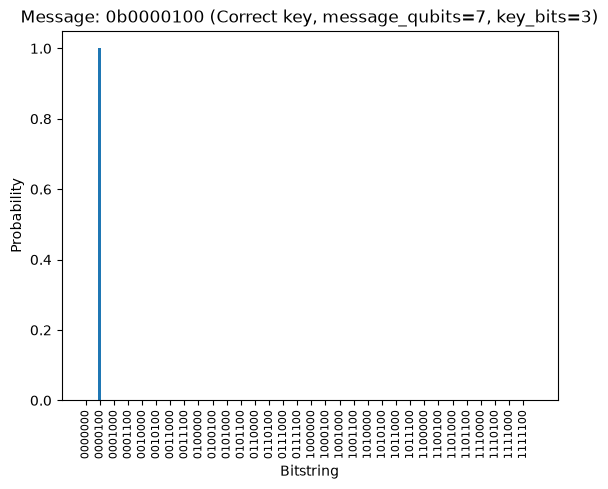

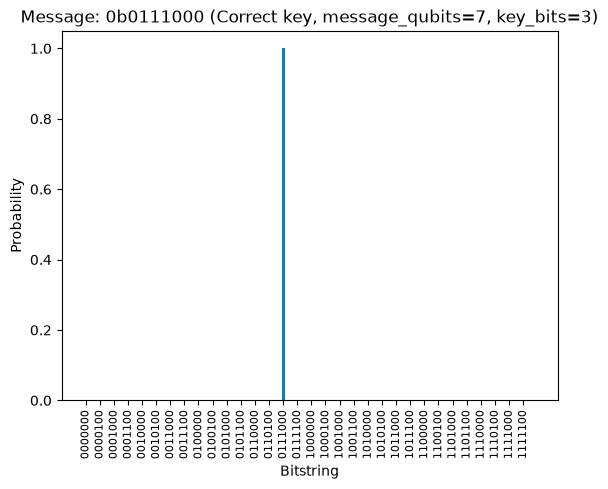

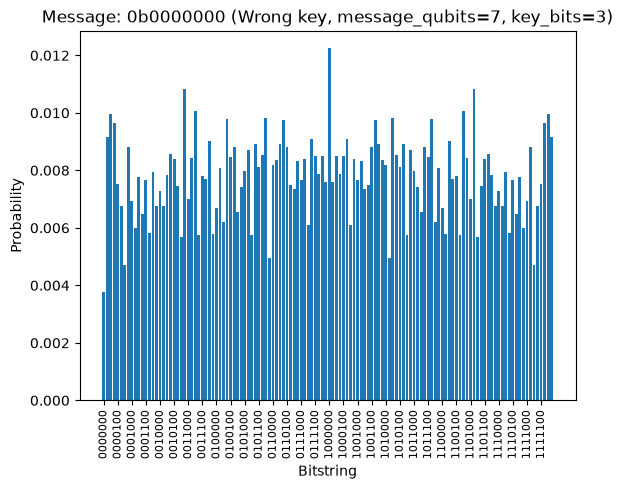

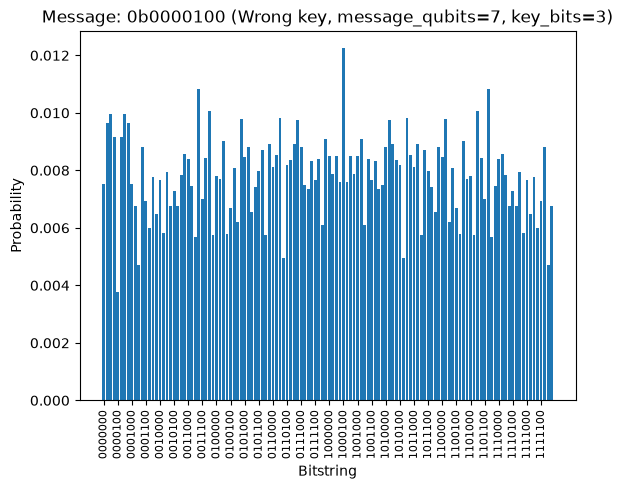

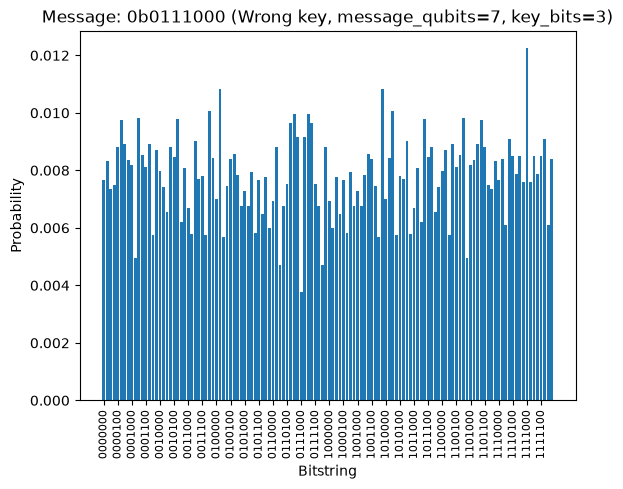

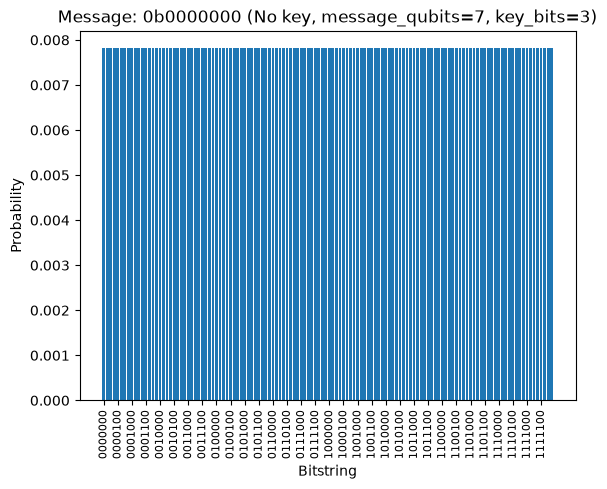

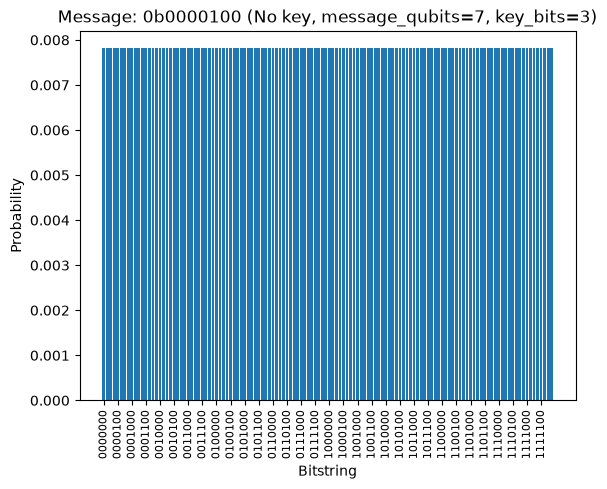

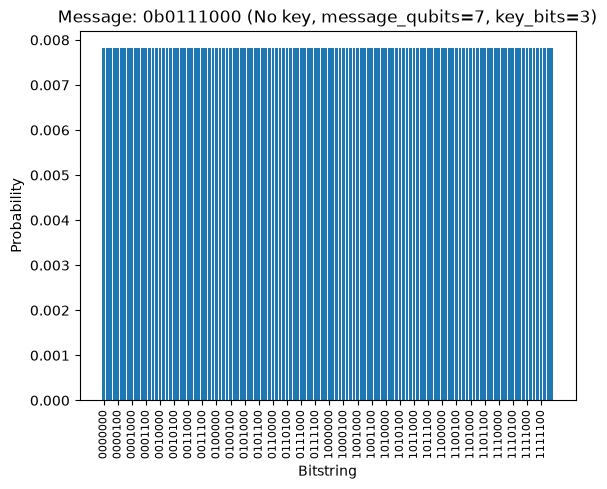

Starting entropy calculation of correct keys...
Starting entropy calculation of wrong keys...
Starting entropy calculation of no keys...
The averages of Shannon entropy (message qubits = 7, key bits = 3)
Average entropy (correct keys): 0.00
Average entropy (wrong keys): 6.40
Average entropy (no keys): 7.00


In [6]:
# Changing global state

old_MESSAGE_QUBITS = MESSAGE_QUBITS
old_KEY_BITS = KEY_BITS
try:
    new_message_qubits = [4, 5, 6, 7]
    new_key_bits = [1, 2, 3]
    new_system_settings = itertools.product(new_message_qubits, new_key_bits)
    
    for system_setting in new_system_settings:
        MESSAGE_QUBITS = system_setting[0]
        KEY_BITS = system_setting[1]

        print(f"Calculating for message_qubits={MESSAGE_QUBITS}, key_bits={KEY_BITS}")
        
        selected_messages_stat(selected_messages)
        entropy_avg = entropy_stat()
        print(f"The averages of Shannon entropy (message qubits = {MESSAGE_QUBITS}, key bits = {KEY_BITS})")
        print(f"Average entropy (correct keys): {entropy_avg[0]:.2f}")
        print(f"Average entropy (wrong keys): {entropy_avg[1]:.2f}")
        print(f"Average entropy (no keys): {entropy_avg[2]:.2f}")
    
    
finally:
    MESSAGE_QUBITS = old_MESSAGE_QUBITS
    KEY_BITS = old_KEY_BITS